In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm
from scipy.stats import ks_2samp, bootstrap, ecdf
%matplotlib inline

Load pings per user per day calculated in filter_sensitivity.ipynb.

In [8]:
df_merged = pd.read_parquet("/glade/campaign/cisl/aiml/cat_flood/pings_per_user_per_day.parquet")

Get home location info and merge with ping data.

In [11]:
home_loc_df = pd.read_parquet("/glade/work/ggantos/cat-rain/notebooks/home_loc_by_row_group_counties_unfiltered.parquet")

In [14]:
home_loc_all_pings = home_loc_df.loc[df_merged.index]

Plot pings per day for the whole period.

In [16]:
daily_all_ping_counts = np.count_nonzero(~np.isnan(df_merged.values), axis=0)

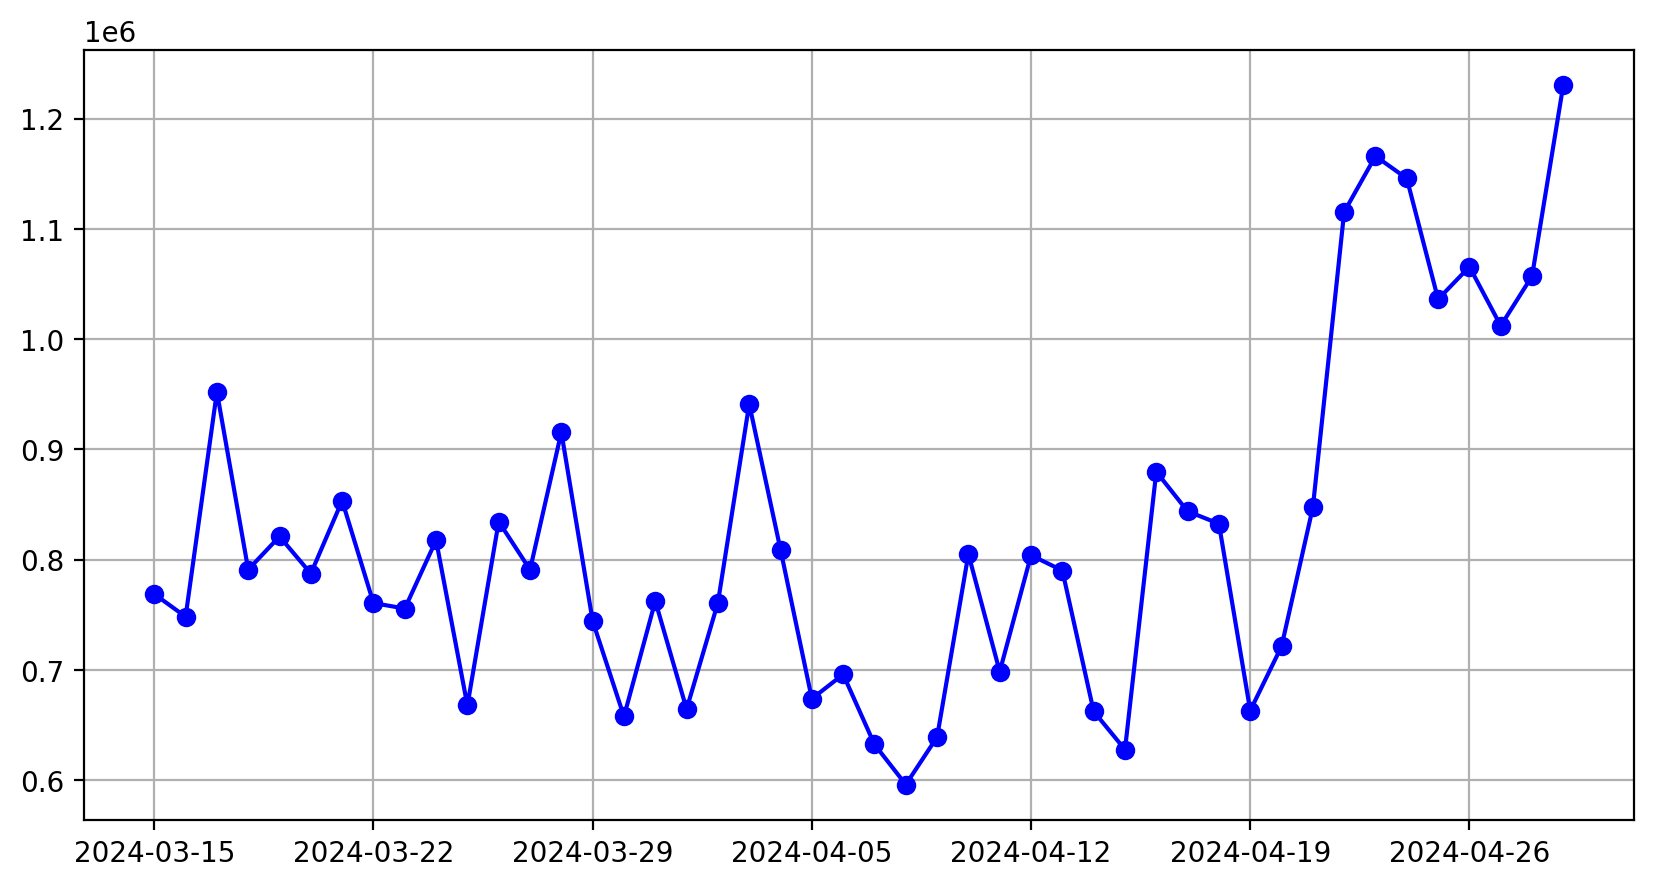

In [26]:
plt.figure(figsize=(10, 5), dpi=200)
plt.plot(pd.DatetimeIndex(df_merged.columns)[46:], daily_all_ping_counts[46:], 'bo-')
plt.xticks(pd.DatetimeIndex(df_merged.columns)[46::7])
plt.grid()

In [66]:
df_merged.columns[46:92]

Index(['2024-03-15', '2024-03-16', '2024-03-17', '2024-03-18', '2024-03-19',
       '2024-03-20', '2024-03-21', '2024-03-22', '2024-03-23', '2024-03-24',
       '2024-03-25', '2024-03-26', '2024-03-27', '2024-03-28', '2024-03-29',
       '2024-03-30', '2024-03-31', '2024-04-01', '2024-04-02', '2024-04-03',
       '2024-04-04', '2024-04-05', '2024-04-06', '2024-04-07', '2024-04-08',
       '2024-04-09', '2024-04-10', '2024-04-11', '2024-04-12', '2024-04-13',
       '2024-04-14', '2024-04-15', '2024-04-16', '2024-04-17', '2024-04-18',
       '2024-04-19', '2024-04-20', '2024-04-21', '2024-04-22', '2024-04-23',
       '2024-04-24', '2024-04-25', '2024-04-26', '2024-04-27', '2024-04-28',
       '2024-04-29'],
      dtype='object')

Identify users that have at least a certain number of pings on at least a certain number of days in the base and AR periods

In [72]:
user_count_dict = {}
ar_count_dict = {}
count_vals = [1, 5, 10]
ar_days = [61]
ar_period_days = [60, 61, 62, 63]
baseline_days = (np.arange(0, 92) >= 46) & ~np.isin(np.arange(0, 92), ar_period_days)
counts = df_merged.values
for count in count_vals:
    user_count_dict[count] = np.count_nonzero(counts[:, baseline_days] >= count, axis=1)
    ar_count_dict[count] = np.count_nonzero(counts[:, ar_days] >= count, axis=1)

In [73]:
filtered_users = df_merged.index[(user_count_dict[5] >= 15) & (ar_count_dict[5] == 1)]
home_loc_df.loc[filtered_users].groupby("county").count()["duration"]

county
LA    175917
SB      7136
VE     20744
Name: duration, dtype: int64

Filter home locations down to the users that meet the ping count.

In [74]:
user_home_meta = home_loc_df.loc[filtered_users]

In [38]:
user_home_meta

,duration,lat,lng,zipcode,row_group,county
uid,,,,,,
0000292d773980cdf3926d34b3275e95a56d5e31e3c90fdb9e70a25cfcd8750f,10 days 23:21:31,33.924514,-117.942556,90631,0,LA
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,21 days 11:29:35,34.099681,-117.846496,91724,0,LA
0000c10b4b076e94d56542852a5096f8e0a7d237de8fa35bc1f676cd2eef1ea6,2 days 23:30:42,34.238634,-118.474438,91343,0,LA
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,4 days 23:15:49,34.107017,-118.200225,90042,0,LA
000113ce3330cb882b58599914da21cdc3f0519a1c23811ef47349987eee7a26,8 days 04:17:32,34.173285,-118.346366,91505,1,LA
...,...,...,...,...,...,...
ffff52e9005912d53fd42be3347e917540ccb8ad1ca3764f0b441b483c837def,13 days 19:51:23,34.248904,-118.278683,91042,75016,LA
ffff60adceb58ca8239ad352d86e5cb8eacc30af241ba6bc806d012703330a31,3 days 23:46:06,34.143763,-117.861769,91741,75016,LA
ffff88da7942d1c71e8cc139e95c8ae3d0b36061725b3b840b352a340ca7f8e4,5 days 14:43:57,33.907301,-118.164314,90723,75017,LA


In [39]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))

In [98]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))[46:]
ar_file = ar_files[0]
ar_date = ar_file.split("/")[-1].split("_")[1]
metric = 'distance_straight_line'
df_0 = pd.read_parquet(ar_file, columns=["uid", metric])
df_0 = df_0.set_index("uid")
df_joined = user_home_meta.join(df_0)
new_col = f"{metric}_{ar_date}"
df_joined = df_joined.rename(columns={metric: new_col})
metric_cols = [new_col]
for ar_file in tqdm(ar_files[1:]):
    ar_date = ar_file.split("/")[-1].split("_")[1]
    df_l = pd.read_parquet(ar_file, columns=["uid", metric])
    df_l = df_l.set_index("uid")
    df_joined = df_joined.join(df_l)
    new_col = f"{metric}_{ar_date}"
    df_joined = df_joined.rename(columns={metric: f"{metric}_{ar_date}"})
    metric_cols.append(new_col)


100%|██████████| 45/45 [00:34<00:00,  1.31it/s]


(array([38844., 26236., 13378.,  4054.,     0.,     0.,     0.,     0.,
            0.,     0.,     0.,     0.]),
 array([30., 35., 40., 45., 50., 55., 60., 65., 70., 75., 80., 85., 90.]),
 <BarContainer object of 12 artists>)

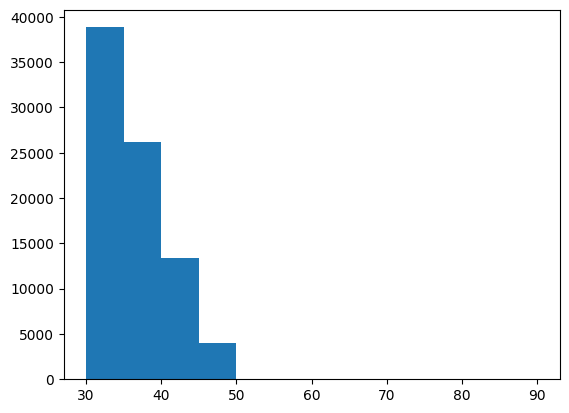

In [99]:
plt.hist(np.sum(~np.isnan(df_joined[metric_cols].values), axis=1), bins=np.arange(30, 95, 5))

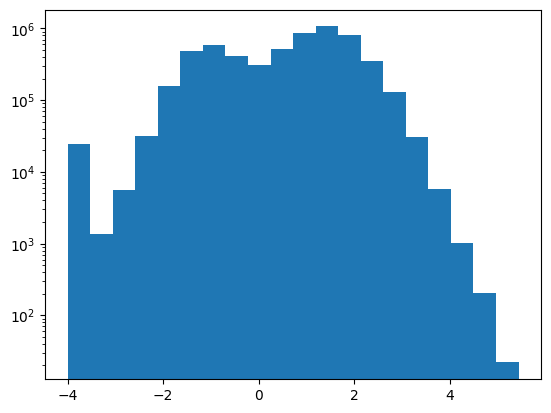

In [100]:
plt.hist(np.log10(np.maximum(df_joined[metric_cols].values.ravel(), 1e-4)), bins=20)
plt.gca().set_yscale("log")

In [101]:
ar_event_dates = ["2024-03-29", "2024-03-30", "2024-03-31", "2024-04-01"]
ar_event_cols = [f"{metric}_{date}" for date in ar_event_dates]
baseline_flag = ~np.isin(metric_cols, ar_event_cols)
baseline_cols = pd.Series(metric_cols)[baseline_flag]
ar_event_flag = np.isin(metric_cols, ar_event_cols)

In [130]:
df_joined[baseline_cols]

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.577447,0.148050,0.072076,4.518701,4.157835,0.701545,10.297275,24.818907,0.115762,0.046051
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,27.763370,NaN,NaN,0.405339,37.286825,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.046567,0.022539,NaN,40.281856,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.020226,7.104384,38.966774,NaN,19.843855,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.789224,2.291767,1.353006,0.884060,0.178346,43.555438,1.450768,1.218656,113.242463,0.469914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.019192,0.070023,2.216624,3.955427,188.914653,53.337993,135.176858,1081.390252,516.811776,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.261490,15.068729,13.907677,NaN,NaN,NaN,NaN,0.083488,10.206489,8.337815
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,33.446894,NaN,3.285429,87.149954,1.710188,5.083226,NaN,NaN,104.336061,NaN


In [102]:
base_log_metric = np.log(np.maximum(df_joined[metric_cols], 1e-4))
people_means = np.nanmean(base_log_metric, axis=1)
people_sds  = np.nanstd(base_log_metric, axis=1)
people_ns = np.count_nonzero(~np.isnan(base_log_metric), axis=1)
z_score = (base_log_metric[f"{metric}_2024-03-31"]  - people_means) / (people_sds)
z_score_samp = (base_log_metric[f"{metric}_2024-03-31"]  - people_means) / (people_sds/ np.sqrt(people_ns))

In [103]:
z_score_base = (base_log_metric - people_means.reshape(-1, 1)) / (people_sds.reshape(-1, 1))

In [104]:
m_date = "2024-03-30"
m_col = f"{metric}_{m_date}"
good_vals = np.count_nonzero(~np.isnan(df_joined[baseline_cols.values]), axis=1)
metric_quantiles = ((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1)[m_col] - 1) / good_vals)

In [105]:
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
daily_ar_data_sub = daily_ar_data.loc[user_home_meta.index]

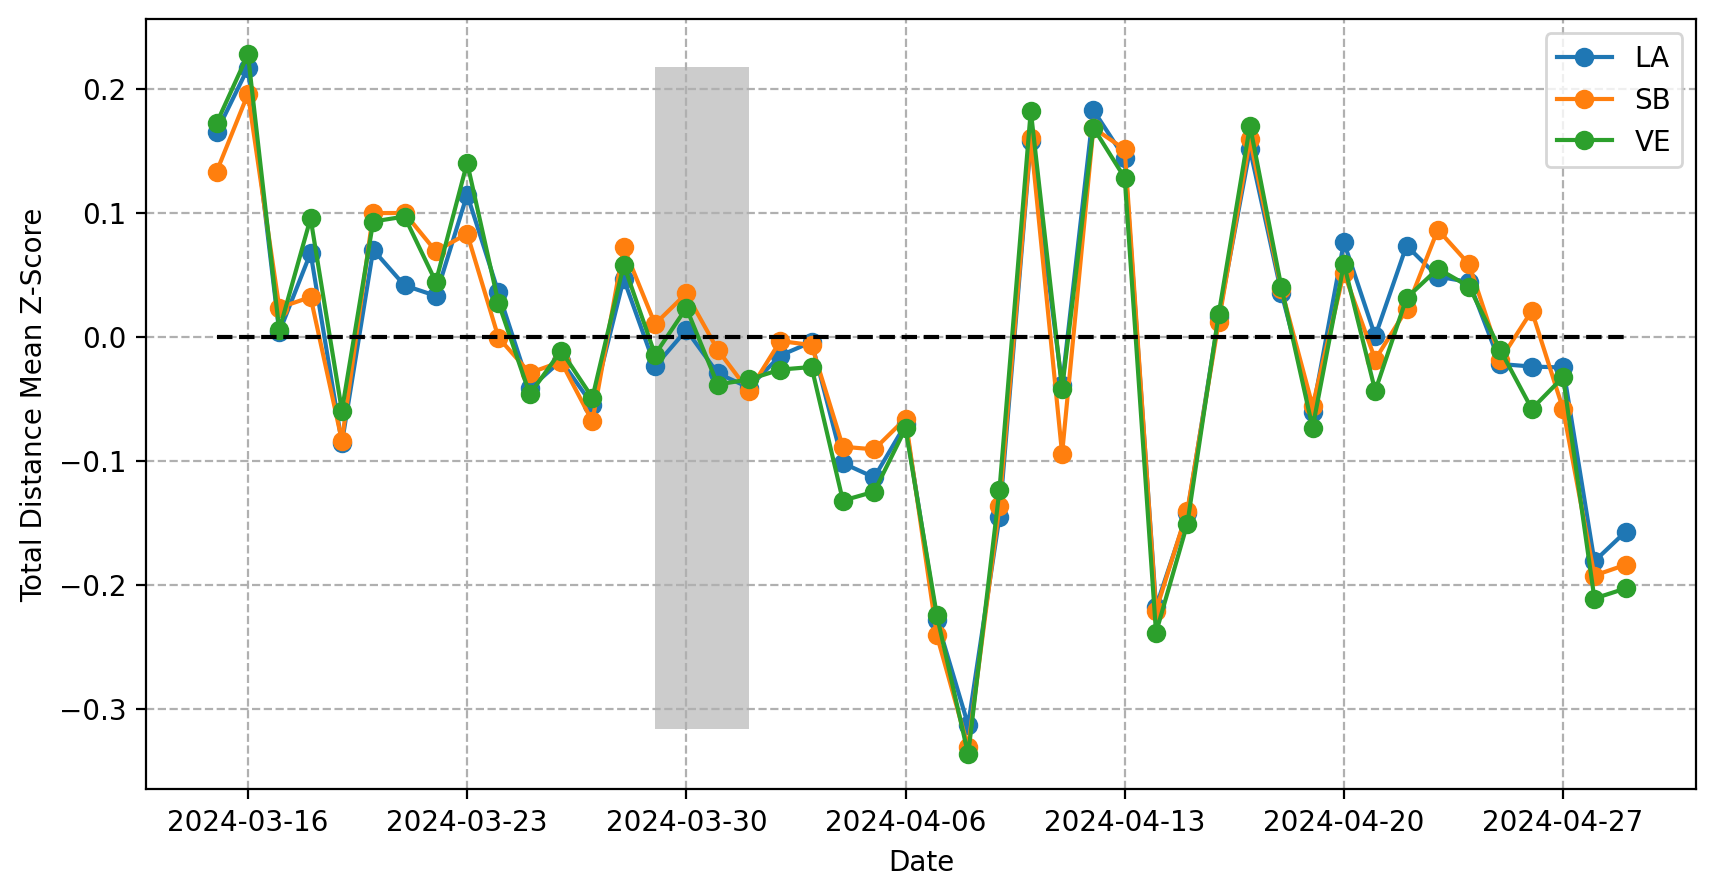

In [109]:
dates = [x.split("_")[-1] for x in metric_cols]
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces = []
for county in counties:
    traces.append(np.nanmean(z_score_base.loc[user_home_meta["county"] == county], axis=0))
d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces):
    plt.plot(d_idx, trace, marker='o', label=counties[t])
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()
plt.savefig("mean_dist_z_score.png", bbox_inches="tight")

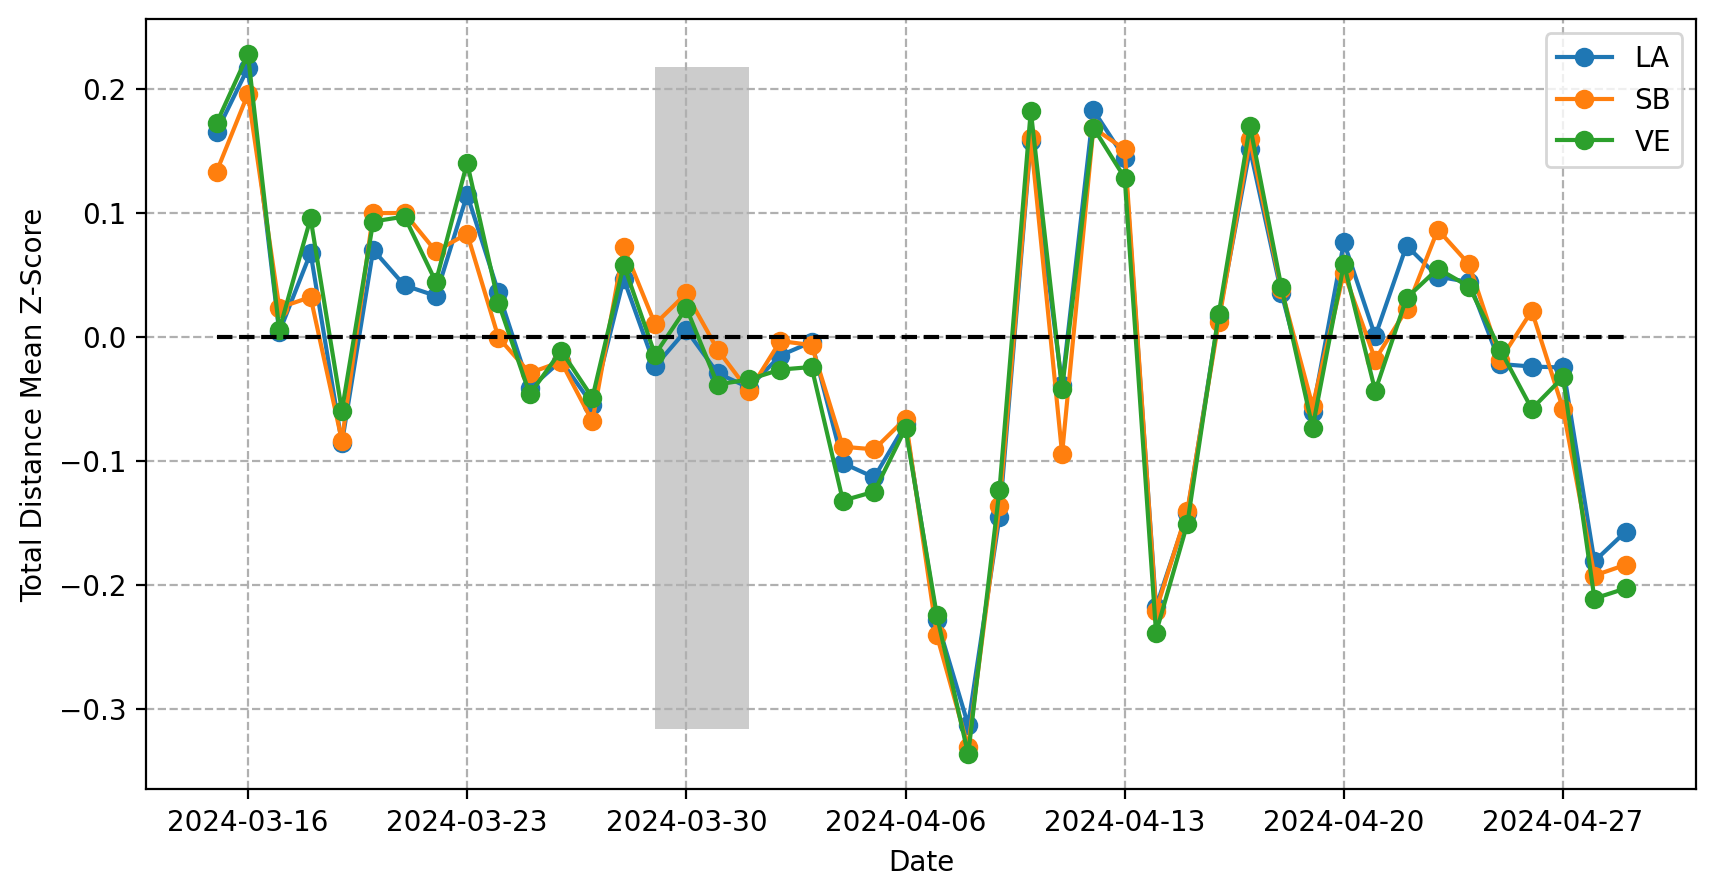

In [109]:
dates = [x.split("_")[-1] for x in metric_cols]
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces = []
for county in counties:
    traces.append(np.nanmean(z_score_base.loc[user_home_meta["county"] == county], axis=0))
d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces):
    plt.plot(d_idx, trace, marker='o', label=counties[t])
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()
plt.savefig("mean_dist_z_score.png", bbox_inches="tight")

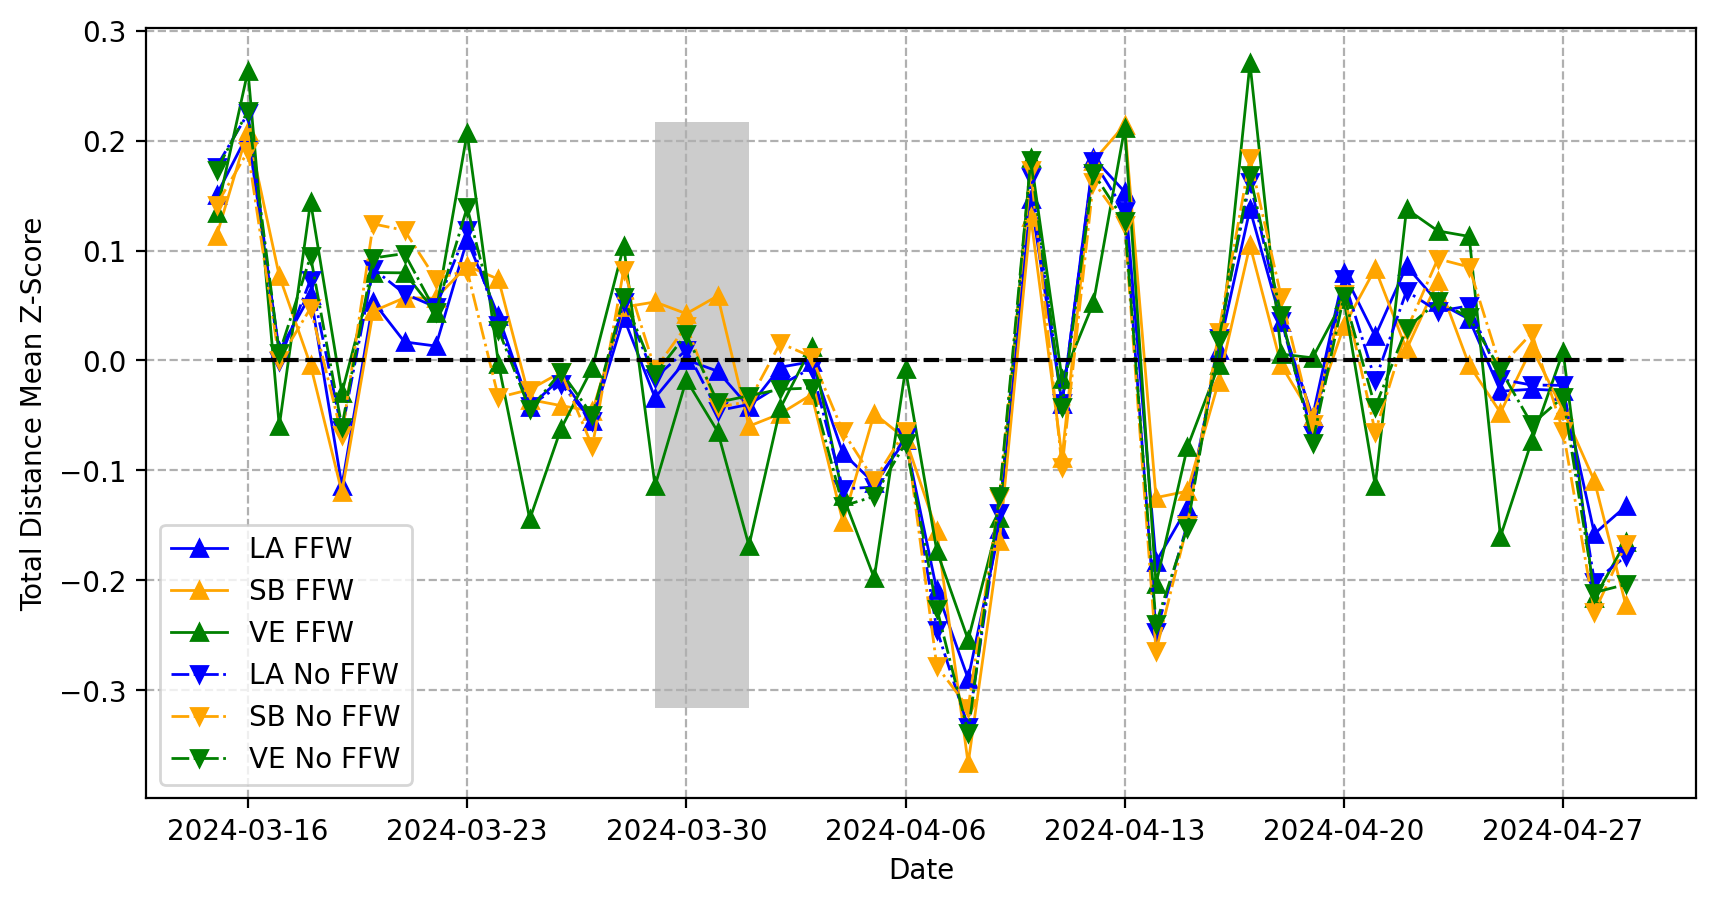

In [110]:
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces_pos = []
traces_neg = []
colors = ['blue', 'orange', 'green']
pos_ls = '-'
neg_ls = '-.'
pos_mark = '^'
neg_mark = 'v'
for county in counties:
    traces_pos.append(np.nanmean(z_score_base.loc[(user_home_meta["county"] == county) & daily_ar_data_sub["FFW"]], axis=0))
    traces_neg.append(np.nanmean(z_score_base.loc[(user_home_meta["county"] == county) & ~daily_ar_data_sub["FFW"]], axis=0))

d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces_pos):
    plt.plot(d_idx, trace, marker=pos_mark, color=colors[t], ls=pos_ls, label=counties[t] + " FFW", lw=1)
for t, trace in enumerate(traces_neg):
    plt.plot(d_idx, trace, marker=neg_mark, color=colors[t], ls=neg_ls, label=counties[t] + " No FFW", lw=1)
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()

plt.savefig("mean_dist_z_score_pos_neg.png", bbox_inches="tight")

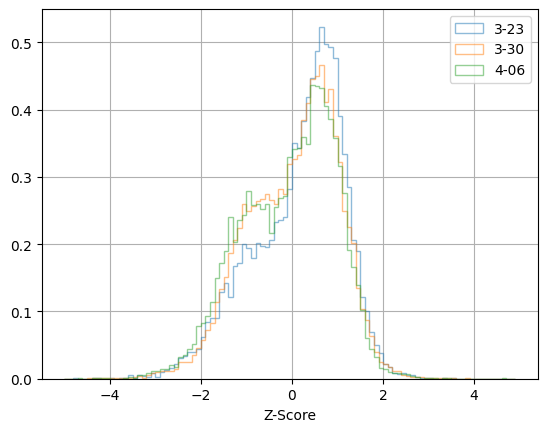

In [111]:
z_score_base.loc[daily_ar_data_sub["county"] == "VE", f"{metric}_2024-03-23"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, cumulative=False, 
                                                                                   label="3-23", alpha=0.5,
                                                                                   histtype='step')
z_score_base.loc[daily_ar_data_sub["county"] == "VE", f"{metric}_2024-03-30"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, cumulative=False, label="3-30", 
                                                                                   alpha=0.5,
                                                                                   histtype='step')
z_score_base.loc[daily_ar_data_sub["county"] == "VE", f"{metric}_2024-04-06"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, 
                                                                                   cumulative=False, label="4-06", alpha=0.5,
                                                                                  histtype='step')

plt.xlabel("Z-Score")
plt.legend()
plt.savefig("day_comp_hist.png", bbox_inches="tight")

In [89]:
uid_counts = np.count_nonzero(~np.isnan(z_score_base), axis=1)
row_align = np.argsort(uid_counts)

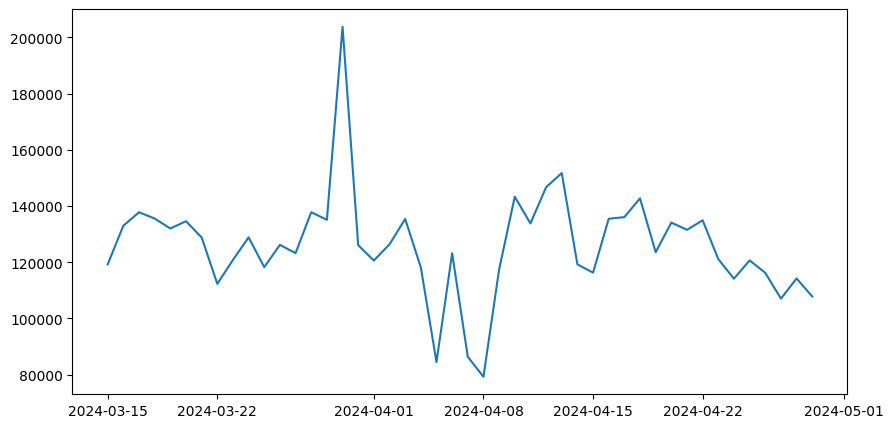

In [90]:
plt.figure(figsize=(10, 5))
plt.plot(pd.DatetimeIndex(dates)[46:], np.count_nonzero(~np.isnan(z_score_base),axis=0)[46:])

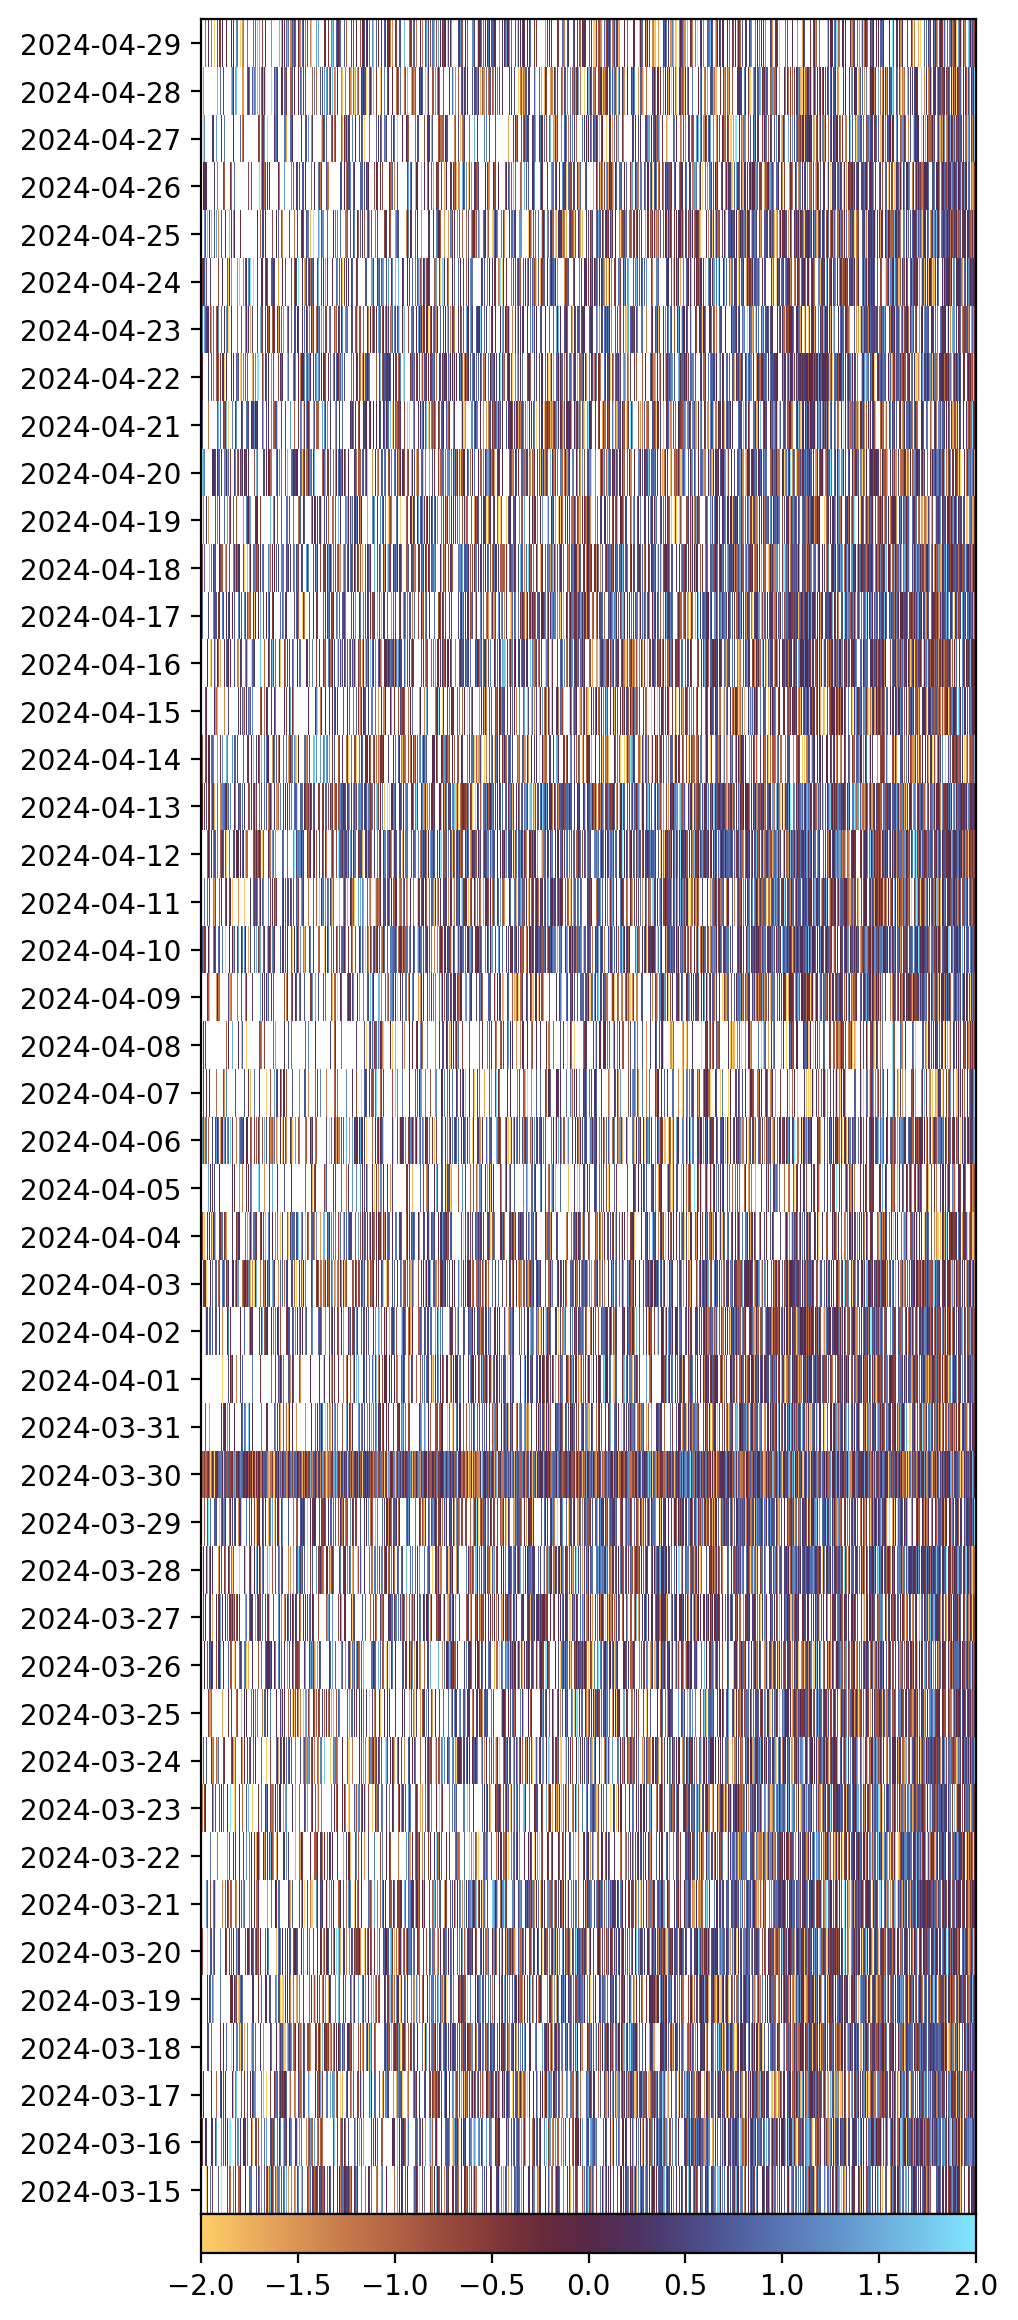

In [112]:
plt.figure(figsize=(5, 15), dpi=200)
plt.pcolormesh(z_score_base.iloc[row_align].T, vmin=-2, vmax=2, cmap="managua")
_ = plt.yticks(np.arange(0.5, z_score_base.shape[1] + 0.5), dates)
plt.xticks([])
plt.colorbar(orientation="horizontal", pad=0, fraction=0.05)
plt.savefig("zscore_uid_dist.png", dpi=300, bbox_inches="tight")

In [47]:
z_score_base

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.440524,-1.193785,-1.356735,0.225841,0.191277,-0.547710,0.567893,0.933231,-1.295951,-1.356735
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.447048,NaN,NaN,-1.399252,0.575874,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-1.821616,-1.821616,NaN,0.597083,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-2.170026,0.034444,0.914514,NaN,0.565580,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.463521,0.623834,0.282542,0.006940,-1.029771,2.530890,0.327722,0.214813,3.149690,-0.402340
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.928691,-1.928691,-0.867631,-0.669326,0.654599,0.221539,0.539982,1.252048,0.999220,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.318452,0.665885,0.626638,NaN,NaN,NaN,NaN,-1.788952,0.475185,0.376202
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.273592,NaN,-0.486337,0.587221,-0.700154,-0.343404,NaN,NaN,0.646165,NaN


In [94]:
ks_2samp(z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-03-23"].dropna(),
          z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-04-06"].dropna())

KstestResult(statistic=np.float64(0.07956613037384053), pvalue=np.float64(1.4116221771832854e-289), statistic_location=np.float64(0.09184194395623618), statistic_sign=np.int8(-1))

In [529]:
z_score_base

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.786118,-7.550158,-8.580745,1.428344,1.209740,-3.464022,3.591673,5.902274,-8.196311,-8.580745
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2.719288,NaN,NaN,-8.511316,3.502906,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-12.620528,-12.620528,NaN,4.136714,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-14.229815,0.225861,5.996869,NaN,3.708756,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.967983,3.994486,1.809149,0.044440,-6.593751,16.205605,2.098445,1.375474,20.167855,-2.576232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-11.889247,-11.889247,-5.348439,-4.126003,4.035217,1.365660,3.328671,7.718140,6.159603,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-8.127484,4.104792,3.862859,NaN,NaN,NaN,NaN,-11.027839,2.929239,2.319063
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.708584,NaN,-3.037176,3.667193,-4.372461,-2.144560,NaN,NaN,4.035299,NaN


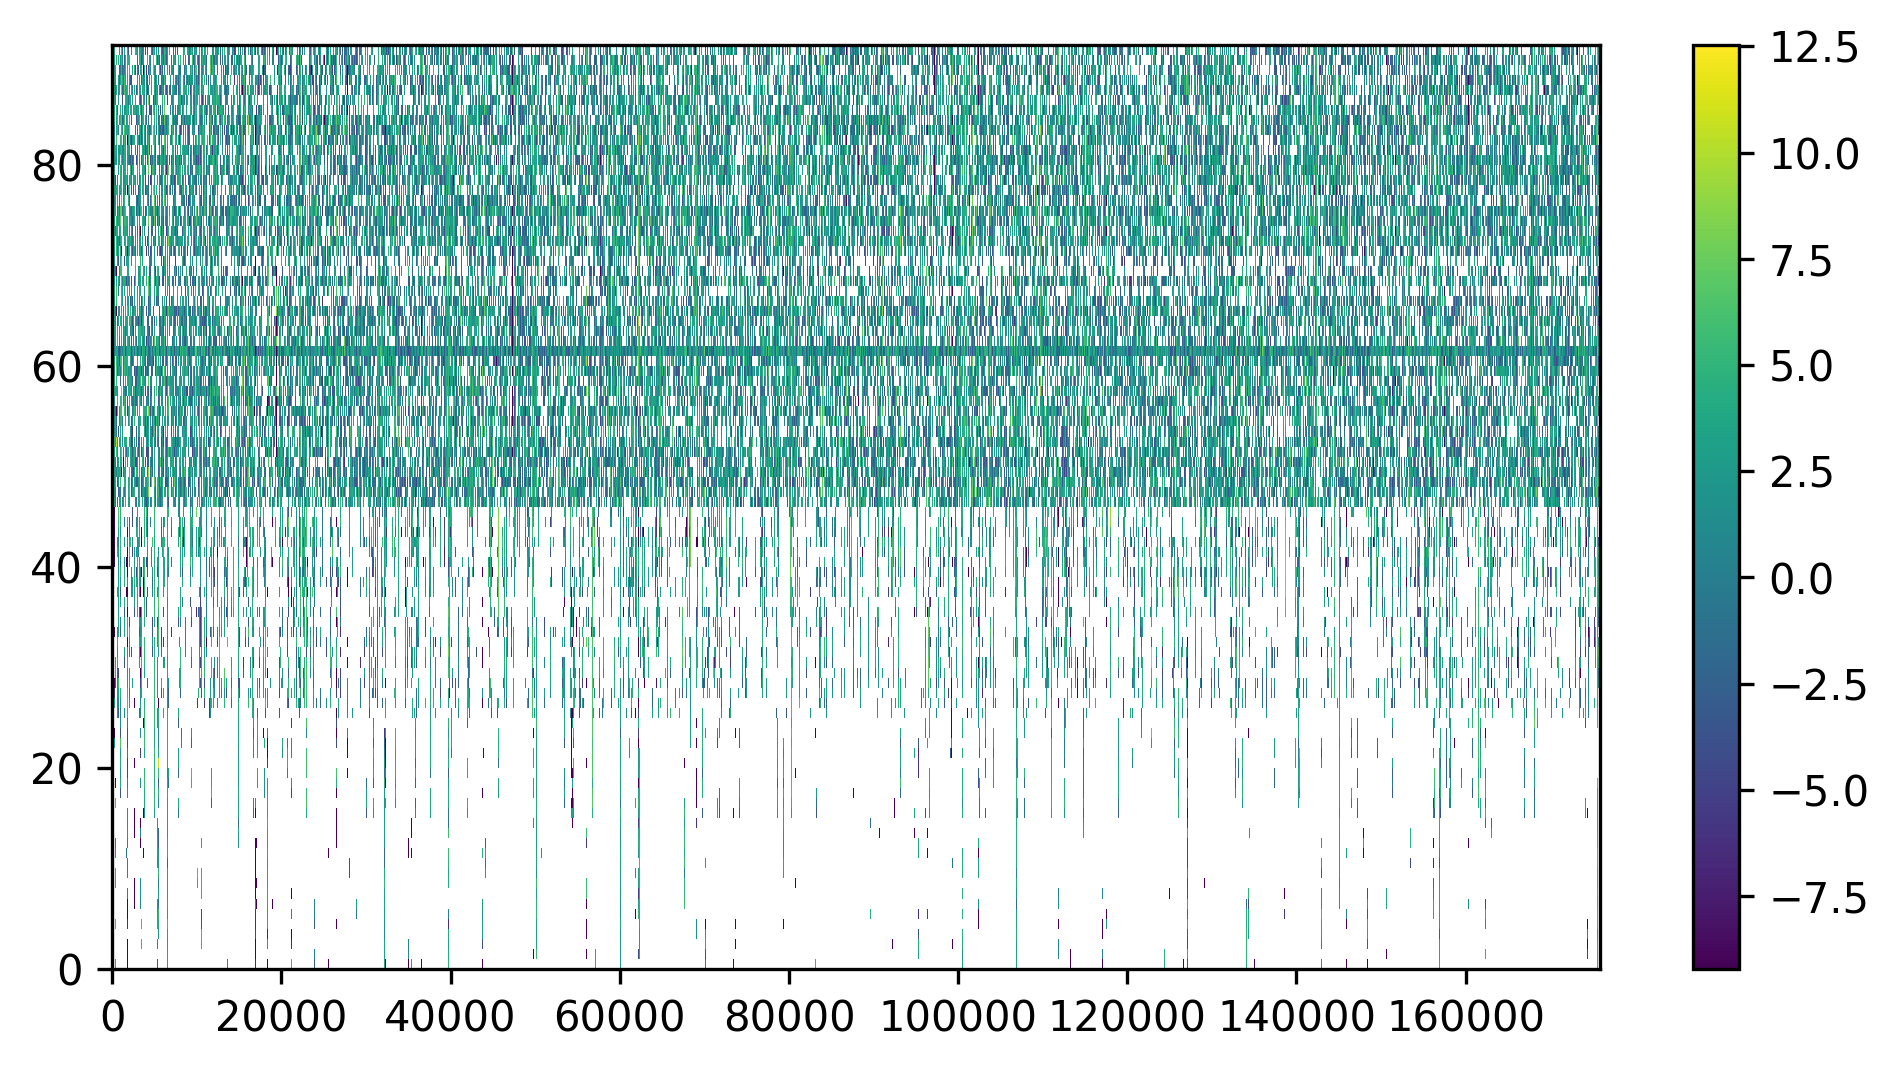

In [95]:
plt.figure(figsize=(8, 4), dpi=300)
plt.pcolormesh(base_log_metric[daily_ar_data_sub["county"] == "LA"].T)
plt.colorbar()

In [407]:
base_log_metric.columns[46:]

Index(['distance_straight_line_2024-03-15',
       'distance_straight_line_2024-03-16',
       'distance_straight_line_2024-03-17',
       'distance_straight_line_2024-03-18',
       'distance_straight_line_2024-03-19',
       'distance_straight_line_2024-03-20',
       'distance_straight_line_2024-03-21',
       'distance_straight_line_2024-03-22',
       'distance_straight_line_2024-03-23',
       'distance_straight_line_2024-03-24',
       'distance_straight_line_2024-03-25',
       'distance_straight_line_2024-03-26',
       'distance_straight_line_2024-03-27',
       'distance_straight_line_2024-03-28',
       'distance_straight_line_2024-04-02',
       'distance_straight_line_2024-04-03',
       'distance_straight_line_2024-04-04',
       'distance_straight_line_2024-04-05',
       'distance_straight_line_2024-04-06',
       'distance_straight_line_2024-04-07',
       'distance_straight_line_2024-04-08',
       'distance_straight_line_2024-04-09',
       'distance_straight_line_2

In [185]:
m_date = "2024-03-30"
m_col = f"{metric}_{m_date}"
good_vals = np.count_nonzero(~np.isnan(df_joined[baseline_cols.values]), axis=1)
metric_quantiles = ((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1)[m_col] - 1) / good_vals)
all_quantiles = ((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1) - 1) / good_vals.reshape(-1, 1))


In [183]:
metric_quantiles

uid
0000292d773980cdf3926d34b3275e95a56d5e31e3c90fdb9e70a25cfcd8750f    0.793103
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99    0.944444
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4    0.222222
000113ce3330cb882b58599914da21cdc3f0519a1c23811ef47349987eee7a26    0.178571
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4    0.473684
                                                                      ...   
fffeff7aa60ecfde112609f32fcee989a8b134379f255ac35b015803216ad4c0    0.888889
fffeffd69e034688698f5e1537cc707055798167994b71f0d9c29b10e6145d17    0.909091
ffff0966698509c8a2ca9ebb8749a197592f6389bbe71ebaa73240edcbf30060    0.320000
ffff52e9005912d53fd42be3347e917540ccb8ad1ca3764f0b441b483c837def    0.000000
ffff8c6eca66e179685ada7106011ec94a8e64faf7aa0fe83cbf978fa6972c13    0.842105
Name: distance_straight_line_2024-03-30, Length: 203797, dtype: float64

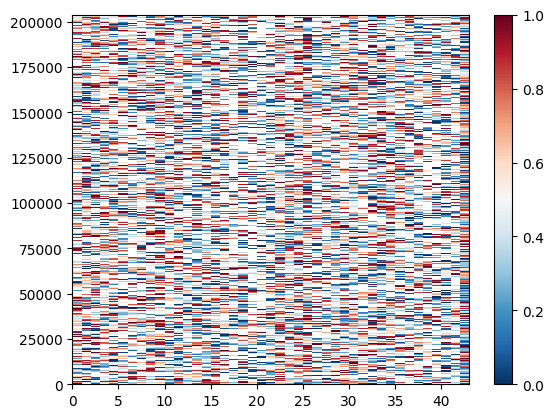

In [186]:
plt.pcolormesh(all_quantiles, cmap="RdBu_r")
plt.colorbar()

In [191]:
np.count_nonzero(metric_quantiles == 1)

9217

In [306]:
np.nanmax(df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1).values)

np.float64(89.0)

In [308]:
good_vals.min()

np.int64(28)

In [114]:
user_home_meta[m_col] = metric_quantiles

county
LA    Axes(0.125,0.11;0.775x0.77)
SB    Axes(0.125,0.11;0.775x0.77)
VE    Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

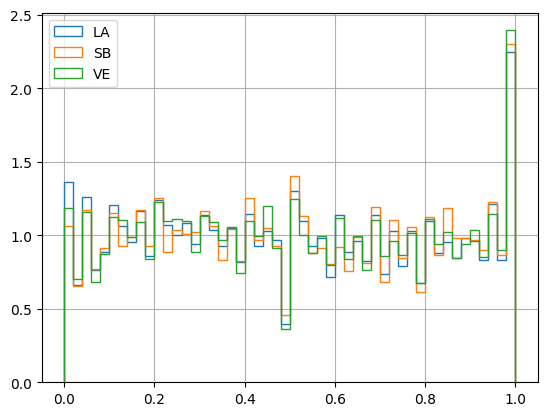

In [180]:
user_home_meta.groupby("county")[m_col].hist(bins=50, 
                                            histtype="step", density=True, 
                                            legend=True)


In [116]:
ar_mrms_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_*.parquet"))

In [187]:
ar_mrms_files

['/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-27_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-28_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-29_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-30_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-31_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-04-01_PST_chunked.parquet']

In [117]:
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
daily_ar_data_sub = daily_ar_data.loc[user_home_meta.index]

<Axes: >

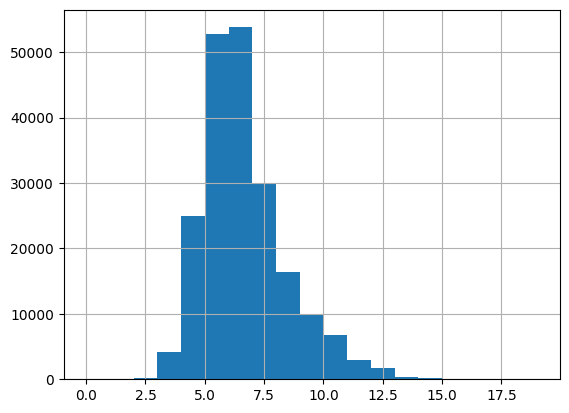

In [121]:
daily_ar_data_sub["precip_max"].hist(bins=np.arange(0, 20))
#plt.gca().set_yscale('log')

In [317]:
daily_ar_data_sub.columns

Index(['duration', 'lat_home', 'lng_home', 'zipcode', 'row_group', 'county',
       'number_of_visits', 'distance_straight_line', 'jump_lengths',
       'radius_of_gyration', 'num_stops', 'max_distance_from_home', 'date',
       'FFW', 'precip_max', 'precip_sum', 'streamflow_max', 'streamflow_sum',
       'distance_straight_line_2024-03-30', 'streamflow_max_flag',
       'precip_sum_flag', 'precip_max_flag'],
      dtype='object')

In [170]:
daily_ar_data_sub[m_col] = metric_quantiles
daily_ar_data_sub["streamflow_max_flag"] = daily_ar_data_sub["streamflow_max"] >= 1.1
daily_ar_data_sub["precip_max_flag"] = daily_ar_data_sub["precip_max"] >= 6.4

In [171]:
daily_ar_data_sub.groupby("streamflow_max_flag").count()

,duration,lat_home,lng_home,zipcode,row_group,county,number_of_visits,distance_straight_line,jump_lengths,radius_of_gyration,num_stops,max_distance_from_home,date,FFW,precip_max,precip_sum,streamflow_max,streamflow_sum,distance_straight_line_2024-03-30,precip_max_flag
streamflow_max_flag,,,,,,,,,,,,,,,,,,,,
False,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123
True,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674


precip_max_flag
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

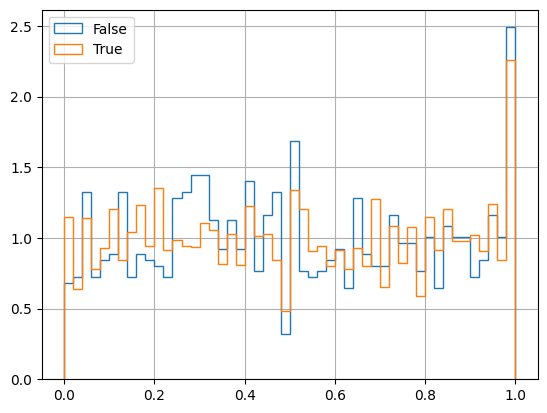

In [158]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "SB"].groupby("precip_max_flag")[m_col].hist(bins=50, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=False)


In [154]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "LA")], 
         metric_quantiles[(~daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "LA")])

KstestResult(statistic=np.float64(0.009901526357842583), pvalue=np.float64(0.0003797345770280587), statistic_location=np.float64(0.6153846153846154), statistic_sign=np.int8(-1))

In [155]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "VE")], 
         metric_quantiles[(~daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "VE")])

KstestResult(statistic=np.float64(0.009488710547647217), pvalue=np.float64(0.7971219749434347), statistic_location=np.float64(0.7916666666666666), statistic_sign=np.int8(-1))

In [156]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "SB")], 
         metric_quantiles[(~daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "SB")])

KstestResult(statistic=np.float64(0.034901514051452795), pvalue=np.float64(0.1590862141287467), statistic_location=np.float64(0.23333333333333334), statistic_sign=np.int8(1))

streamflow_max_flag
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

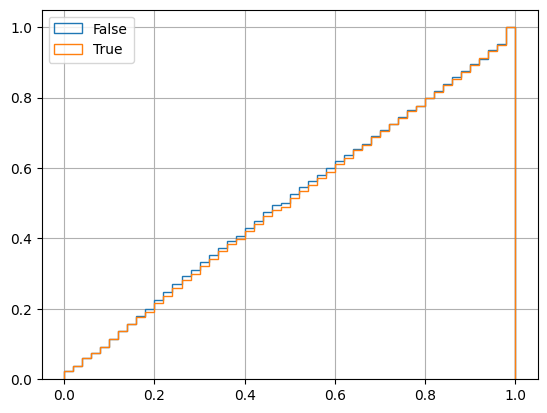

In [175]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "VE"].groupby("streamflow_max_flag")[m_col].hist(bins=50, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=True)


In [178]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["streamflow_max_flag"]) & (daily_ar_data_sub["county"] == "VE")], 
         metric_quantiles[(~daily_ar_data_sub["streamflow_max_flag"]) & (daily_ar_data_sub["county"] == "VE")])

KstestResult(statistic=np.float64(0.013740544191791992), pvalue=np.float64(0.3034727827363506), statistic_location=np.float64(0.4634146341463415), statistic_sign=np.int8(-1))

FFW
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

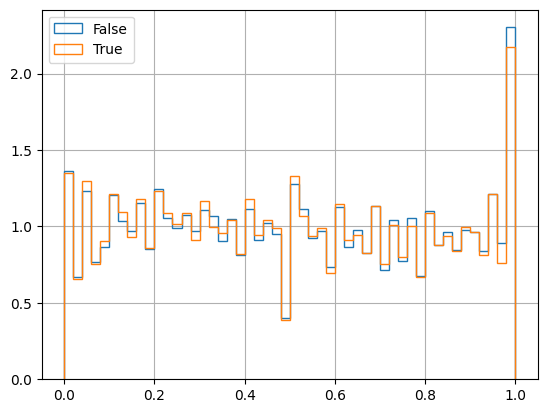

In [134]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "LA"].groupby("FFW")[m_col].hist(bins=50, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=False)

In [127]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")])

KstestResult(statistic=np.float64(0.007652804065844454), pvalue=np.float64(0.012074331416729716), statistic_location=np.float64(0.6410256410256411), statistic_sign=np.int8(1))

In [128]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")])

KstestResult(statistic=np.float64(0.04764445411348328), pvalue=np.float64(0.37049701432587934), statistic_location=np.float64(0.7037037037037037), statistic_sign=np.int8(1))

In [129]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "SB")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "SB")])

KstestResult(statistic=np.float64(0.015431707676440254), pvalue=np.float64(0.8545535143443042), statistic_location=np.float64(0.21875), statistic_sign=np.int8(-1))

<Axes: >

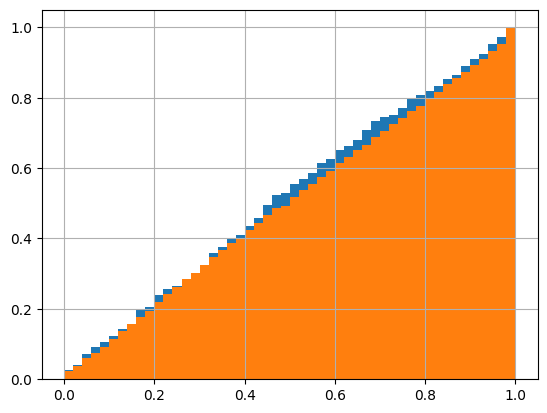

In [135]:
metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")].hist(density=True,cumulative=True, bins=50)
metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")].hist(density=True, cumulative=True, bins=50)